In [20]:
import os
import numpy as np
from dataclasses import dataclass
import matplotlib.pyplot as plt

In [21]:
%pip install tensorflow


[notice] A new release of pip available: 22.3.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [22]:
%pip install --upgrade certifi


[notice] A new release of pip available: 22.3.1 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Dataset & Preprocessing

In [23]:
from tensorflow.keras.datasets import cifar10

(x_train, y_train), (x_test, y_test) = cifar10.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Test images: (10000, 32, 32, 3)
Test labels: (10000, 1)


In [24]:
y_train = y_train.ravel()
# y_test = y_test.ravel()

In [25]:
rng = np.random.default_rng(42)

train_indices = []
val_indices = []

for label in range(10):
    class_indices = np.where(y_train == label)[0]

    selected_indices = rng.choice(class_indices, size=1000, replace=False)

    train_indices.extend(selected_indices[:800])
    val_indices.extend(selected_indices[800:])

train_indices = np.array(train_indices)
val_indices = np.array(val_indices)

x_train_subset = x_train[train_indices]
y_train_subset = y_train[train_indices]

x_val = x_train[val_indices]
y_val = y_train[val_indices]

In [26]:
x_train_subset = x_train_subset.astype(np.float64).reshape(-1, 3072) / 255.0
x_val = x_val.astype(np.float64).reshape(-1, 3072) / 255.0

print("Training:", x_train_subset.shape, y_train_subset.shape)
print("Validation:", x_val.shape, y_val.shape)

Training: (8000, 3072) (8000,)
Validation: (2000, 3072) (2000,)


In [27]:
class Parameter:
    def __init__(self, data):
        self.data = data
        self.grad = np.zeros_like(data)


class ReLU:
    def __init__(self):
        self.x = None

    def __call__(self, x):
        self.x = x
        return np.maximum(x, 0)

    def backward(self, grad):
        return grad * (self.x > 0)


class Sigmoid:
    def __init__(self):
        self.out = None

    def __call__(self, x):
        x = np.clip(x, -500, 500)
        self.out = 1.0 / (1.0 + np.exp(-x))
        return self.out

    def backward(self, grad):
        return grad * self.out * (1.0 - self.out)


## Question 1: Implement Forward Propagation

In [28]:
def softmax(logits):
    """Convert logits to probabilities using stable softmax."""
    shifted = logits - np.max(logits, axis=1, keepdims=True)
    exp_logits = np.exp(shifted)
    return exp_logits / np.sum(exp_logits, axis=1, keepdims=True)


class Linear:
    def __init__(
        self,
        in_features,
        out_features,
        rng=None,
        init_method="xavier"
    ):
        if rng is None:
            rng = np.random.default_rng()

        # He initialization for ReLU; Xavier for sigmoid.
        if init_method == "he":
            std = np.sqrt(2.0 / in_features)
        elif init_method == "xavier":
            std = np.sqrt(2.0 / (in_features + out_features))
        else:
            raise ValueError("init_method must be 'he' or 'xavier'")

        self.W = Parameter(
            rng.normal(0.0, std, size=(out_features, in_features))
        )
        self.b = Parameter(np.zeros(out_features))
        self.x = None

    def __call__(self, x):
        self.x = x
        return x @ self.W.data.T + self.b.data

    def backward(self, grad):
        self.W.grad += grad.T @ self.x
        self.b.grad += np.sum(grad, axis=0)
        return grad @ self.W.data


class NeuralNetwork:
    def __init__(
        self,
        input_features,
        hidden_features,
        output_features,
        activation="relu",
        seed=42
    ):
        # Support either one hidden layer or two hidden layers.
        if isinstance(hidden_features, int):
            hidden_sizes = [hidden_features]
        else:
            hidden_sizes = list(hidden_features)

        if len(hidden_sizes) not in (1, 2):
            raise ValueError("Use one or two hidden layers.")

        if any(width <= 0 for width in hidden_sizes):
            raise ValueError("Hidden widths must be positive.")

        if activation not in ("relu", "sigmoid"):
            raise ValueError("Activation must be relu or sigmoid.")

        rng = np.random.default_rng(seed)
        self.activation_name = activation

        dimensions = (
            [input_features] + hidden_sizes + [output_features]
        )

        self.layers = []

        for i in range(len(dimensions) - 1):
            is_hidden = i < len(hidden_sizes)

            init_method = (
                "he"
                if is_hidden and activation == "relu"
                else "xavier"
            )

            self.layers.append(
                Linear(
                    dimensions[i],
                    dimensions[i + 1],
                    rng=rng,
                    init_method=init_method
                )
            )

        # One activation object per hidden layer.
        if activation == "relu":
            self.activations = [
                ReLU() for _ in hidden_sizes
            ]
        else:
            self.activations = [
                Sigmoid() for _ in hidden_sizes
            ]

    def __call__(self, x):
        """Return output logits."""
        a = x

        for layer, activation in zip(
            self.layers[:-1], self.activations
        ):
            a = activation(layer(a))

        return self.layers[-1](a)

    def predict_proba(self, x):
        """Return class probabilities."""
        return softmax(self(x))

    def backward(self, grad):
        # Start with the output layer.
        grad = self.layers[-1].backward(grad)

        # Propagate gradients backwards through hidden layers.
        for layer, activation in zip(
            reversed(self.layers[:-1]),
            reversed(self.activations)
        ):
            grad = activation.backward(grad)
            grad = layer.backward(grad)

    def parameters(self):
        """Yield all trainable weights and biases."""
        for layer in self.layers:
            yield layer.W
            yield layer.b

    @property
    def parameter_count(self):
        return sum(p.data.size for p in self.parameters())

In [29]:
# Test a 3072 -> 64 -> 10 neural network.
test_model = NeuralNetwork(
    input_features=3072,
    hidden_features=64,
    output_features=10,
    activation="relu",
    seed=42
)

rng_test = np.random.default_rng(7)
dummy_x = rng_test.random((5, 3072))

probabilities = test_model.predict_proba(dummy_x)

print("Probability shape:", probabilities.shape)
print("Probability sums:", probabilities.sum(axis=1))

print("\nParameter shapes:")
for p in test_model.parameters():
    print(p.data.shape)

print("\nParameter count:", test_model.parameter_count)

assert probabilities.shape == (5, 10)
assert np.allclose(probabilities.sum(axis=1), 1.0)
assert np.all(probabilities >= 0)
assert test_model.parameter_count == 197322

print("\nAll tests passed!")

Probability shape: (5, 10)
Probability sums: [1. 1. 1. 1. 1.]

Parameter shapes:
(64, 3072)
(64,)
(10, 64)
(10,)

Parameter count: 197322

All tests passed!


## Question 2: Implement Backpropagation and Training

In [30]:
class SGD:
    def __init__(self, model, lr=0.01, momentum=0.0):
        self.params = list(model.parameters())
        self.lr = lr
        self.momentum = momentum
        self.velocity = [np.zeros_like(p.data) for p in self.params]

    def zero_grad(self):
        for p in self.params:
            p.grad.fill(0)

    def step(self):
        for p, v in zip(self.params, self.velocity):
            v *= self.momentum
            v += p.grad
            p.data -= self.lr * v

### Backpropagation Sanity Check

In [31]:

# Example: 10-class categorical cross-entropy
rng = np.random.default_rng(42)
model = NeuralNetwork(4, 16, 10)
optimizer = SGD(model, lr=0.01, momentum=0.9)

x = rng.standard_normal((8, 4))
labels = rng.integers(0, 10, size=8)

logits = model(x)
shifted = logits - logits.max(axis=1, keepdims=True)
exp_logits = np.exp(shifted)
probs = exp_logits / exp_logits.sum(axis=1, keepdims=True)

loss = -np.log(probs[np.arange(len(labels)), labels]).mean()

# Equivalent to loss.backward(): seed the gradient at the output.
grad = probs.copy()
grad[np.arange(len(labels)), labels] -= 1
grad /= len(labels)
model.backward(grad)

optimizer.step()
optimizer.zero_grad()

print("Loss:", loss)


Loss: 2.713297803777909


### Gradient Verification Using Finite Differences

In [32]:
# Verify analytical gradients against numerical gradients.

rng_check = np.random.default_rng(123)

check_model = NeuralNetwork(
    input_features=4,
    hidden_features=5,
    output_features=3,
    activation="relu",
    seed=123
)

X_check = rng_check.normal(size=(4, 4))
y_check = np.array([0, 2, 1, 2])


def check_loss(model, X, y):
    """Mean categorical cross-entropy."""
    probabilities = model.predict_proba(X)
    correct_probs = probabilities[np.arange(len(y)), y]
    return -np.mean(np.log(np.clip(correct_probs, 1e-12, 1.0)))


# Calculate analytical gradients using backpropagation.
for parameter in check_model.parameters():
    parameter.grad.fill(0)

logits = check_model(X_check)
probabilities = softmax(logits)

grad = probabilities.copy()
grad[np.arange(len(y_check)), y_check] -= 1
grad /= len(y_check)

check_model.backward(grad)

parameters = list(check_model.parameters())

# Check one weight in the first hidden layer and one in the output layer.
checks = [
    ("First-layer weight", parameters[0], (0, 0)),
    ("Output-layer weight", parameters[2], (0, 0)),
]

epsilon = 1e-5

for name, parameter, index in checks:
    analytical = parameter.grad[index]
    original_value = parameter.data[index]

    parameter.data[index] = original_value + epsilon
    loss_plus = check_loss(check_model, X_check, y_check)

    parameter.data[index] = original_value - epsilon
    loss_minus = check_loss(check_model, X_check, y_check)

    parameter.data[index] = original_value

    numerical = (loss_plus - loss_minus) / (2 * epsilon)

    print(f"\n{name}")
    print(f"Analytical gradient: {analytical:.8f}")
    print(f"Numerical gradient:  {numerical:.8f}")
    print(f"Absolute difference: {abs(analytical - numerical):.8e}")

    assert np.isclose(
        analytical, numerical, rtol=1e-3, atol=1e-5
    ), f"Gradient check failed for {name}"

print("\nAll gradient checks passed!")


First-layer weight
Analytical gradient: -0.37951826
Numerical gradient:  -0.37951826
Absolute difference: 8.30424618e-12

Output-layer weight
Analytical gradient: -0.38831329
Numerical gradient:  -0.38831329
Absolute difference: 5.17269561e-12

All gradient checks passed!


### Mini-Batch Training and Epoch-wise Evaluation

We train the neural network using mini-batch SGD or momentum-based SGD.
Training data is shuffled before each epoch. After every epoch, we
evaluate loss and accuracy on the complete training and validation
subsets. The earliest checkpoint achieving the best validation accuracy
is retained.

In [39]:
import time


def loss_and_gradient(logits, labels):
    """
    Calculate mean categorical cross-entropy and its gradient
    with respect to the output logits.
    """
    batch_size = len(labels)

    # Stable log-softmax computation.
    shifted = logits - np.max(logits, axis=1, keepdims=True)
    log_probs = shifted - np.log(
        np.sum(np.exp(shifted), axis=1, keepdims=True)
    )

    loss = -np.mean(
        log_probs[np.arange(batch_size), labels]
    )

    probabilities = np.exp(log_probs)

    # Gradient of softmax + cross-entropy.
    grad = probabilities.copy()
    grad[np.arange(batch_size), labels] -= 1
    grad /= batch_size

    return loss, grad


def evaluate_model(model, X, y, batch_size=512):
    """
    Evaluate loss and accuracy on an entire dataset in batches.
    No parameter updates are performed.
    """
    total_loss = 0.0
    total_correct = 0
    total_examples = len(y)

    for start in range(0, total_examples, batch_size):
        end = min(start + batch_size, total_examples)

        X_batch = X[start:end]
        y_batch = y[start:end]

        logits = model(X_batch)
        batch_loss, _ = loss_and_gradient(logits, y_batch)

        total_loss += batch_loss * len(y_batch)
        total_correct += np.sum(
            np.argmax(logits, axis=1) == y_batch
        )

    return {
        "loss": total_loss / total_examples,
        "accuracy": total_correct / total_examples
    }


def train_model(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=10,
    batch_size=128,
    learning_rate=0.01,
    optimizer_name="momentum",
    momentum=0.9,
    shuffle_seed=2026,
    verbose=True
):
    """
    Train a NumPy neural network using mini-batch SGD.

    optimizer_name:
        "sgd"      -> ordinary mini-batch SGD
        "momentum" -> mini-batch SGD with momentum

    Retains the earliest checkpoint with the highest validation accuracy.
    """
    if optimizer_name not in ("sgd", "momentum"):
        raise ValueError("Use 'sgd' or 'momentum'.")

    if epochs < 1 or batch_size < 1:
        raise ValueError("epochs and batch_size must be positive.")

    # Momentum velocities are initialized to zero once per run.
    momentum_value = momentum if optimizer_name == "momentum" else 0.0

    optimizer = SGD(
        model,
        lr=learning_rate,
        momentum=momentum_value
    )

    # Separate generator for reproducible training-data shuffling.
    shuffle_rng = np.random.default_rng(shuffle_seed)

    history = []
    best_val_accuracy = -1.0
    best_epoch = None
    best_state = None

    start_time = time.perf_counter()

    for epoch in range(1, epochs + 1):
        epoch_start = time.perf_counter()

        # Shuffle the training data before every epoch.
        permutation = shuffle_rng.permutation(len(X_train))

        for start in range(0, len(X_train), batch_size):
            indices = permutation[start:start + batch_size]

            X_batch = X_train[indices]
            y_batch = y_train[indices]

            # Clear gradients before processing the next mini-batch.
            optimizer.zero_grad()

            # Forward pass.
            logits = model(X_batch)

            # Mean cross-entropy and output gradient.
            loss, grad = loss_and_gradient(logits, y_batch)

            # Manual backpropagation and parameter update.
            model.backward(grad)
            optimizer.step()

        # Evaluate on the COMPLETE training and validation subsets.
        train_metrics = evaluate_model(
            model, X_train, y_train
        )
        val_metrics = evaluate_model(
            model, X_val, y_val
        )

        epoch_seconds = time.perf_counter() - epoch_start

        record = {
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "epoch_seconds": epoch_seconds
        }

        history.append(record)
        # Log epoch-wise metrics when a W&B run is active.
        if wandb.run is not None:
            wandb.log(
                {
                    "epoch": epoch,
                    "train/loss": record["train_loss"],
                    "train/accuracy": record["train_accuracy"],
                    "validation/loss": record["val_loss"],
                    "validation/accuracy": record["val_accuracy"],
                    "epoch_seconds": record["epoch_seconds"],
                },
                step=epoch
            )

        # Strict > preserves the earliest epoch when accuracy ties.
        if val_metrics["accuracy"] > best_val_accuracy:
            best_val_accuracy = val_metrics["accuracy"]
            best_epoch = epoch

            best_state = [
                parameter.data.copy()
                for parameter in model.parameters()
            ]

        if verbose:
            print(
                f"Epoch {epoch:02d}/{epochs} | "
                f"Train loss: {record['train_loss']:.4f} | "
                f"Train accuracy: {record['train_accuracy']:.4f} | "
                f"Val loss: {record['val_loss']:.4f} | "
                f"Val accuracy: {record['val_accuracy']:.4f} | "
                f"Time: {epoch_seconds:.2f}s"
            )

    total_seconds = time.perf_counter() - start_time

    # Restore the best validation checkpoint from this run.
    for parameter, saved_value in zip(
        model.parameters(), best_state
    ):
        parameter.data[...] = saved_value

    summary = {
        "best_epoch": best_epoch,
        "best_val_accuracy": best_val_accuracy,
        "training_time_seconds": total_seconds,
        "best_state": best_state
    }

    return history, summary

In [34]:
# Small smoke test: do not start the full experiments yet.

test_rng = np.random.default_rng(99)

small_train_idx = test_rng.choice(
    len(x_train_subset), size=256, replace=False
)
small_val_idx = test_rng.choice(
    len(x_val), size=128, replace=False
)

X_small_train = x_train_subset[small_train_idx]
y_small_train = y_train_subset[small_train_idx]

X_small_val = x_val[small_val_idx]
y_small_val = y_val[small_val_idx]

smoke_model = NeuralNetwork(
    input_features=3072,
    hidden_features=32,
    output_features=10,
    activation="relu",
    seed=42
)

smoke_history, smoke_summary = train_model(
    model=smoke_model,
    X_train=X_small_train,
    y_train=y_small_train,
    X_val=X_small_val,
    y_val=y_small_val,
    epochs=2,
    batch_size=64,
    learning_rate=0.01,
    optimizer_name="momentum",
    momentum=0.9,
    shuffle_seed=2026
)

print("\nSmoke test completed.")
print("Epochs recorded:", len(smoke_history))
print("Best epoch:", smoke_summary["best_epoch"])
print(
    "Best validation accuracy:",
    smoke_summary["best_val_accuracy"]
)

assert len(smoke_history) == 2
assert 1 <= smoke_summary["best_epoch"] <= 2

print("All training-loop checks passed!")

Epoch 01/2 | Train loss: 2.2808 | Train accuracy: 0.1328 | Val loss: 2.3148 | Val accuracy: 0.1250 | Time: 0.02s
Epoch 02/2 | Train loss: 2.2310 | Train accuracy: 0.1484 | Val loss: 2.3347 | Val accuracy: 0.1016 | Time: 0.01s

Smoke test completed.
Epochs recorded: 2
Best epoch: 1
Best validation accuracy: 0.125
All training-loop checks passed!


## Hyperparameter Tuning

### Weights & Biases Experiment Tracking

In [37]:
%pip install wandb

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.4/18.4 MB 5.2 MB/s eta 0:00:0000:0100:01m
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.3/125.3 kB 9.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 176.5/176.5 kB 11.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 5.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 13.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 488.1/488.1 kB 10.3 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 307.7/307.7 kB 12.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 9.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.3/206.3 kB 18.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 15.9 MB/s eta 0:00:0000:0100:01
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if y

In [38]:
import wandb

wandb.login()


wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: WARNING Invalid choice
wandb: You chose 'Create a W&B account'
wandb: Create an account here: https://forge.coreweave.com/wandb/authorize?signup=true&ref=models
wandb: After creating your account, create a new API key and store it securely.
wandb: No netrc file found, creating one.
wandb: Appending key for api.forge.coreweave.com to your netrc file: /Users/adityajaikumarsharma/.netrc
wandb: Currently logged in as: adee-5aug (adee-5aug-indian-institute-of-technology-patna) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


True

### Run the Six Hyperparameter Configurations

In [40]:
# Six required configurations:
# widths 32, 64, 128 x activations ReLU and sigmoid.

import wandb

PROJECT_NAME = "apr-assignment-3-neural-networks"

EPOCHS = 10
BATCH_SIZE = 128
LEARNING_RATE = 0.01
OPTIMIZER_NAME = "momentum"
MOMENTUM = 0.9

INITIALIZATION_SEED = 42
SHUFFLE_SEED = 2026

configurations = [
    (32, "relu"),
    (32, "sigmoid"),
    (64, "relu"),
    (64, "sigmoid"),
    (128, "relu"),
    (128, "sigmoid"),
]

experiment_results = []

for run_order, (width, activation) in enumerate(
    configurations, start=1
):
    run_name = f"{activation}_width_{width}"

    print("\n" + "=" * 65)
    print(f"Experiment {run_order}/6: {run_name}")
    print("=" * 65)

    # Reinitialize the model for every experiment.
    model = NeuralNetwork(
        input_features=3072,
        hidden_features=width,
        output_features=10,
        activation=activation,
        seed=INITIALIZATION_SEED
    )

    run_config = {
        "architecture": f"3072-{width}-10",
        "hidden_width": width,
        "activation": activation,
        "optimizer": OPTIMIZER_NAME,
        "learning_rate": LEARNING_RATE,
        "momentum": MOMENTUM,
        "batch_size": BATCH_SIZE,
        "epochs": EPOCHS,
        "initialization_seed": INITIALIZATION_SEED,
        "shuffle_seed": SHUFFLE_SEED,
        "training_examples": len(x_train_subset),
        "validation_examples": len(x_val),
    }

    with wandb.init(
        project=PROJECT_NAME,
        name=run_name,
        config=run_config
    ) as run:

        history, summary = train_model(
            model=model,
            X_train=x_train_subset,
            y_train=y_train_subset,
            X_val=x_val,
            y_val=y_val,
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            learning_rate=LEARNING_RATE,
            optimizer_name=OPTIMIZER_NAME,
            momentum=MOMENTUM,
            shuffle_seed=SHUFFLE_SEED,
            verbose=True
        )

        # Save summary information to the W&B run.
        run.summary["best_epoch"] = summary["best_epoch"]
        run.summary["best_validation_accuracy"] = (
            summary["best_val_accuracy"]
        )
        run.summary["parameter_count"] = model.parameter_count
        run.summary["training_time_seconds"] = (
            summary["training_time_seconds"]
        )

    # Retain the history and best validation checkpoint locally.
    experiment_results.append({
        "run_order": run_order,
        "run_name": run_name,
        "hidden_width": width,
        "activation": activation,
        "parameter_count": model.parameter_count,
        "best_epoch": summary["best_epoch"],
        "best_val_accuracy": summary["best_val_accuracy"],
        "training_time_seconds": summary["training_time_seconds"],
        "history": history,
        "best_state": [
            value.copy() for value in summary["best_state"]
        ],
    })

    print(
        f"\nBest validation accuracy: "
        f"{summary['best_val_accuracy']:.4f}"
    )
    print(f"Best epoch: {summary['best_epoch']}")
    print(f"Parameters: {model.parameter_count:,}")

print("\nAll six experiments completed.")


Experiment 1/6: relu_width_32


Epoch 01/10 | Train loss: 2.1891 | Train accuracy: 0.1595 | Val loss: 2.1873 | Val accuracy: 0.1645 | Time: 4.89s
Epoch 02/10 | Train loss: 2.0853 | Train accuracy: 0.2116 | Val loss: 2.0856 | Val accuracy: 0.2155 | Time: 0.35s
Epoch 03/10 | Train loss: 2.0167 | Train accuracy: 0.2542 | Val loss: 2.0220 | Val accuracy: 0.2495 | Time: 0.43s
Epoch 04/10 | Train loss: 1.9778 | Train accuracy: 0.2782 | Val loss: 1.9834 | Val accuracy: 0.2820 | Time: 0.52s
Epoch 05/10 | Train loss: 1.9197 | Train accuracy: 0.3060 | Val loss: 1.9315 | Val accuracy: 0.3000 | Time: 0.67s
Epoch 06/10 | Train loss: 1.8806 | Train accuracy: 0.3154 | Val loss: 1.9022 | Val accuracy: 0.3090 | Time: 1.01s
Epoch 07/10 | Train loss: 1.8712 | Train accuracy: 0.3234 | Val loss: 1.9053 | Val accuracy: 0.3090 | Time: 1.12s
Epoch 08/10 | Train loss: 1.8219 | Train accuracy: 0.3416 | Val loss: 1.8668 | Val accuracy: 0.3255 | Time: 0.38s
Epoch 09/10 | Train loss: 1.8389 | Train accuracy: 0.3229 | Val loss: 1.8910 | Val accur

epoch,▁▂▃▃▄▅▆▆▇█
epoch_seconds,█▁▁▁▂▂▂▁▁▁
train/accuracy,▁▃▅▆▇▇▇█▇█
train/loss,█▆▅▄▃▂▂▁▁▁
validation/accuracy,▁▃▅▆▇▇▇█▇█
validation/loss,█▆▄▄▂▂▂▁▂▁
best_epoch,8
best_validation_accuracy,0.3255
epoch,10
epoch_seconds,0.33115
parameter_count,98666



Best validation accuracy: 0.3255
Best epoch: 8
Parameters: 98,666

Experiment 2/6: sigmoid_width_32


Epoch 01/10 | Train loss: 2.2085 | Train accuracy: 0.1986 | Val loss: 2.2089 | Val accuracy: 0.1945 | Time: 0.40s
Epoch 02/10 | Train loss: 2.0896 | Train accuracy: 0.2724 | Val loss: 2.0904 | Val accuracy: 0.2665 | Time: 0.20s
Epoch 03/10 | Train loss: 2.0114 | Train accuracy: 0.2895 | Val loss: 2.0144 | Val accuracy: 0.2840 | Time: 0.22s
Epoch 04/10 | Train loss: 1.9476 | Train accuracy: 0.3220 | Val loss: 1.9539 | Val accuracy: 0.3170 | Time: 0.20s
Epoch 05/10 | Train loss: 1.9088 | Train accuracy: 0.3295 | Val loss: 1.9203 | Val accuracy: 0.3195 | Time: 0.22s
Epoch 06/10 | Train loss: 1.8842 | Train accuracy: 0.3399 | Val loss: 1.9004 | Val accuracy: 0.3320 | Time: 0.21s
Epoch 07/10 | Train loss: 1.8697 | Train accuracy: 0.3486 | Val loss: 1.8922 | Val accuracy: 0.3285 | Time: 0.22s
Epoch 08/10 | Train loss: 1.8378 | Train accuracy: 0.3540 | Val loss: 1.8619 | Val accuracy: 0.3395 | Time: 0.21s
Epoch 09/10 | Train loss: 1.8213 | Train accuracy: 0.3594 | Val loss: 1.8484 | Val accur

...

epoch,▁▂▃▃▄▅▆▆▇█
epoch_seconds,▂▂▁▂▃▄█▁▁▁
train/accuracy,▁▂▄▅▅▅▆▇▇█
train/loss,█▆▅▄▄▄▃▂▂▁
validation/accuracy,▁▃▃▄▆▅▇▇▇█
validation/loss,█▆▅▄▃▄▂▂▂▁
best_epoch,10
best_validation_accuracy,0.388
epoch,10
epoch_seconds,0.4129
parameter_count,394634



Best validation accuracy: 0.3880
Best epoch: 10
Parameters: 394,634

Experiment 6/6: sigmoid_width_128


Epoch 01/10 | Train loss: 2.0905 | Train accuracy: 0.2517 | Val loss: 2.0922 | Val accuracy: 0.2410 | Time: 0.61s
Epoch 02/10 | Train loss: 1.9715 | Train accuracy: 0.2985 | Val loss: 1.9808 | Val accuracy: 0.2945 | Time: 0.45s
Epoch 03/10 | Train loss: 1.9122 | Train accuracy: 0.3334 | Val loss: 1.9273 | Val accuracy: 0.3175 | Time: 0.43s
Epoch 04/10 | Train loss: 1.8629 | Train accuracy: 0.3520 | Val loss: 1.8848 | Val accuracy: 0.3375 | Time: 0.45s
Epoch 05/10 | Train loss: 1.8389 | Train accuracy: 0.3525 | Val loss: 1.8691 | Val accuracy: 0.3340 | Time: 0.45s
Epoch 06/10 | Train loss: 1.8289 | Train accuracy: 0.3611 | Val loss: 1.8644 | Val accuracy: 0.3385 | Time: 0.46s
Epoch 07/10 | Train loss: 1.8058 | Train accuracy: 0.3775 | Val loss: 1.8467 | Val accuracy: 0.3495 | Time: 0.41s
Epoch 08/10 | Train loss: 1.7870 | Train accuracy: 0.3689 | Val loss: 1.8317 | Val accuracy: 0.3570 | Time: 0.43s
Epoch 09/10 | Train loss: 1.7589 | Train accuracy: 0.3811 | Val loss: 1.8091 | Val accur

epoch,▁▂▃▃▄▅▆▆▇█
epoch_seconds,█▂▂▂▂▃▁▂▂▂
train/accuracy,▁▃▅▆▆▇▇▇██
train/loss,█▆▄▃▃▃▂▂▁▁
validation/accuracy,▁▄▆▇▇▇▇███
validation/loss,█▅▄▃▂▂▂▂▁▁
best_epoch,10
best_validation_accuracy,0.3585
epoch,10
epoch_seconds,0.43936
parameter_count,394634



Best validation accuracy: 0.3585
Best epoch: 10
Parameters: 394,634

All six experiments completed.


## Question 3: Present and Interpret the Results

### Experiment Results and Best Model Selection

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Build a results table from all six completed experiments.
results_df = pd.DataFrame([
    {
        "Run": result["run_name"],
        "Run order": result["run_order"],
        "Hidden width": result["hidden_width"],
        "Activation": result["activation"],
        "Parameters": result["parameter_count"],
        "Best epoch": result["best_epoch"],
        "Best validation accuracy": result["best_val_accuracy"],
        "Training time (seconds)": result["training_time_seconds"],
    }
    for result in experiment_results
])

# Display experiments in their original execution order.
display(
    results_df.sort_values("Run order").round(4)
)

# Apply the assignment's model-selection rules:
# 1. Highest best validation accuracy.
# 2. Fewer parameters when validation accuracy ties.
# 3. Earlier run when both previous criteria tie.
ranked_results = results_df.sort_values(
    by=[
        "Best validation accuracy",
        "Parameters",
        "Run order"
    ],
    ascending=[False, True, True],
    kind="stable"
).reset_index(drop=True)

display(ranked_results.round(4))

# Identify the winning experiment.
winner = ranked_results.iloc[0]
selected_run_name = winner["Run"]

selected_experiment = next(
    result for result in experiment_results
    if result["run_name"] == selected_run_name
)

print("\nSELECTED MODEL")
print("Run:", selected_run_name)
print("Architecture:",
      f"3072 -> {int(winner['Hidden width'])} -> 10")
print("Activation:", winner["Activation"])
print("Parameters:", f"{int(winner['Parameters']):,}")
print("Best epoch:", int(winner["Best epoch"]))
print(
    "Best validation accuracy:",
    f"{winner['Best validation accuracy']:.4f}"
)
print(
    "Training time:",
    f"{winner['Training time (seconds)']:.2f} seconds"
)

,Run,Run order,Hidden width,Activation,Parameters,Best epoch,Best validation accuracy,Training time (seconds)
0,relu_width_32,1,32,relu,98666,8,0.3255,10.4018
1,sigmoid_width_32,2,32,sigmoid,98666,9,0.3505,2.5175
2,relu_width_64,3,64,relu,197322,5,0.3705,4.1299
3,sigmoid_width_64,4,64,sigmoid,197322,10,0.3625,4.2321
4,relu_width_128,5,128,relu,394634,10,0.3880,5.0409
5,sigmoid_width_128,6,128,sigmoid,394634,10,0.3585,4.5740


,Run,Run order,Hidden width,Activation,Parameters,Best epoch,Best validation accuracy,Training time (seconds)
0,relu_width_128,5,128,relu,394634,10,0.3880,5.0409
1,relu_width_64,3,64,relu,197322,5,0.3705,4.1299
2,sigmoid_width_64,4,64,sigmoid,197322,10,0.3625,4.2321
3,sigmoid_width_128,6,128,sigmoid,394634,10,0.3585,4.5740
4,sigmoid_width_32,2,32,sigmoid,98666,9,0.3505,2.5175
5,relu_width_32,1,32,relu,98666,8,0.3255,10.4018



SELECTED MODEL
Run: relu_width_128
Architecture: 3072 -> 128 -> 10
Activation: relu
Parameters: 394,634
Best epoch: 10
Best validation accuracy: 0.3880
Training time: 5.04 seconds


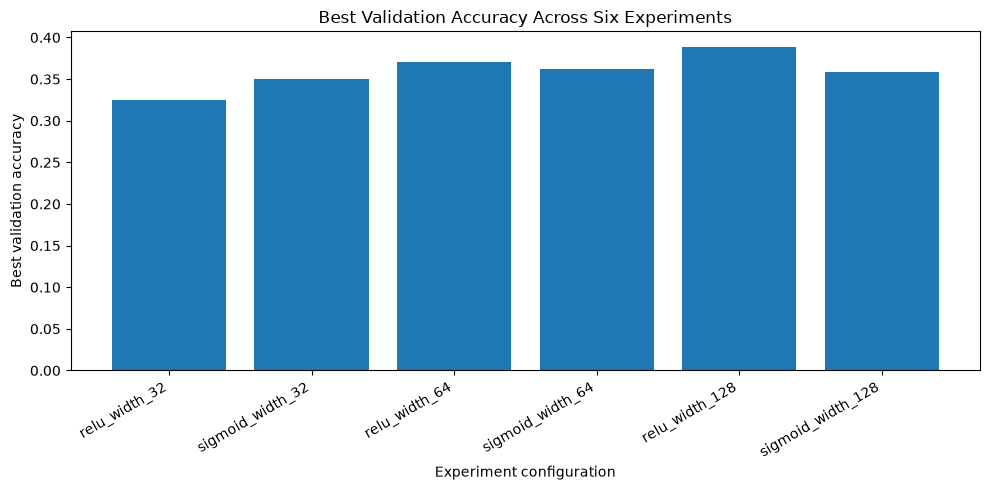

In [44]:
plot_df = results_df.sort_values("Run order")

plt.figure(figsize=(10, 5))
plt.bar(
    plot_df["Run"],
    plot_df["Best validation accuracy"]
)
plt.xlabel("Experiment configuration")
plt.ylabel("Best validation accuracy")
plt.title("Best Validation Accuracy Across Six Experiments")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

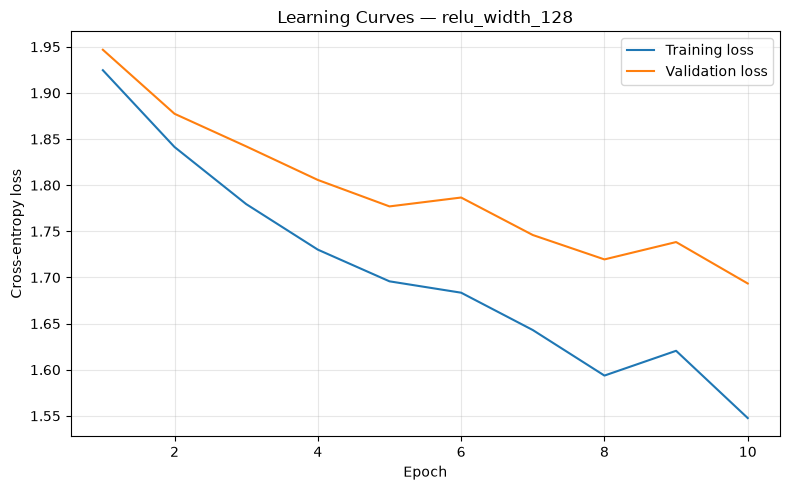

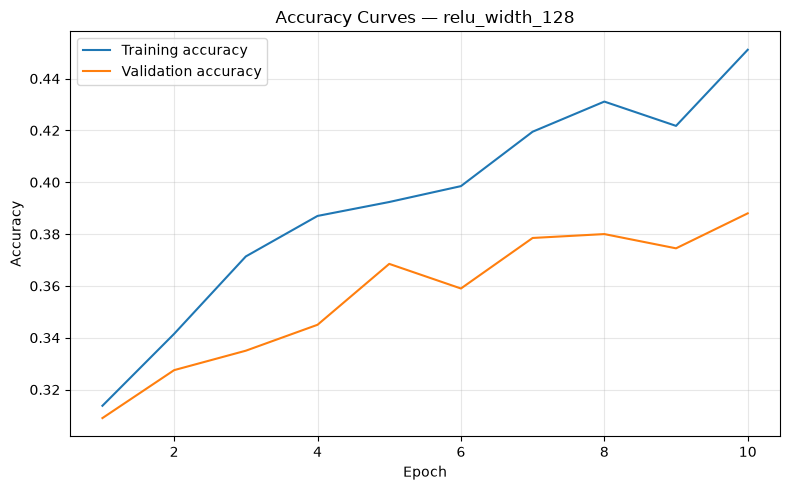

In [45]:
history_df = pd.DataFrame(selected_experiment["history"])
epochs = history_df["epoch"]

# Training and validation loss.
plt.figure(figsize=(8, 5))
plt.plot(epochs, history_df["train_loss"], label="Training loss")
plt.plot(epochs, history_df["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title(f"Learning Curves — {selected_run_name}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Training and validation accuracy.
plt.figure(figsize=(8, 5))
plt.plot(
    epochs,
    history_df["train_accuracy"],
    label="Training accuracy"
)
plt.plot(
    epochs,
    history_df["val_accuracy"],
    label="Validation accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title(f"Accuracy Curves — {selected_run_name}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Comparison and Discussion

**Effect of activation function:** ReLU performs better than sigmoid at
hidden-layer widths 64 and 128 in our experiments. At width 32, sigmoid
performs better than ReLU. This indicates that the effect of the
activation function depends on the hidden-layer width.

**Effect of hidden-layer width:** Increasing the hidden-layer width
improves validation accuracy for ReLU in our experiments. Sigmoid
improves from width 32 to width 64, but its validation accuracy decreases
at width 128.

**Underfitting and overfitting:** The selected model's training loss
decreases across epochs, and its validation loss generally decreases
despite some fluctuations. Training loss remains below validation loss,
indicating a generalization gap. The curves suggest that the model is
learning, although some overfitting may be present. The validation
curves should be considered alongside the training curves when assessing
generalization.

**Selected model:** The model with the highest validation accuracy is
selected using the prescribed tie-breaking rules: fewer parameters for
ties, followed by earlier run order. The official test set is not used
for model selection.

## Question 4: Evaluate the Selected Model

### Restore the Best Checkpoint and Evaluate on CIFAR-10 Test Data


In [46]:
# Reconstruct the winning model from validation-based selection.
selected_width = int(selected_experiment["hidden_width"])
selected_activation = selected_experiment["activation"]

selected_model = NeuralNetwork(
    input_features=3072,
    hidden_features=selected_width,
    output_features=10,
    activation=selected_activation,
    seed=INITIALIZATION_SEED
)

# Restore the best validation checkpoint for this experiment.
for parameter, saved_value in zip(
    selected_model.parameters(),
    selected_experiment["best_state"]
):
    parameter.data[...] = saved_value

print("Selected run:", selected_experiment["run_name"])
print("Hidden width:", selected_width)
print("Activation:", selected_activation)
print("Parameter count:", selected_model.parameter_count)
print("Best epoch:", selected_experiment["best_epoch"])
print(
    "Best validation accuracy:",
    selected_experiment["best_val_accuracy"]
)

Selected run: relu_width_128
Hidden width: 128
Activation: relu
Parameter count: 394634
Best epoch: 10
Best validation accuracy: 0.388


In [47]:
# Prepare the reserved official test set only for final evaluation.
X_test_final = (
    x_test.astype(np.float64).reshape(-1, 3072) / 255.0
)
y_test_final = y_test.ravel().astype(int)

assert X_test_final.shape == (10000, 3072)
assert y_test_final.shape == (10000,)

def final_test_evaluation(model, X, y, batch_size=512):
    total_loss = 0.0
    total_correct = 0
    predictions = []

    for start in range(0, len(y), batch_size):
        end = min(start + batch_size, len(y))
        X_batch = X[start:end]
        y_batch = y[start:end]

        # Forward pass: no gradient update.
        logits = model(X_batch)

        batch_loss, _ = loss_and_gradient(logits, y_batch)
        batch_predictions = np.argmax(logits, axis=1)

        total_loss += batch_loss * len(y_batch)
        total_correct += np.sum(batch_predictions == y_batch)
        predictions.append(batch_predictions)

    predictions = np.concatenate(predictions)

    return {
        "test_loss": total_loss / len(y),
        "test_accuracy": total_correct / len(y),
        "predictions": predictions
    }


# Run final evaluation once, after model selection is complete.
test_results = final_test_evaluation(
    selected_model,
    X_test_final,
    y_test_final
)

y_pred = test_results["predictions"]

print(f"Test loss: {test_results['test_loss']:.4f}")
print(f"Test accuracy: {test_results['test_accuracy']:.4f}")
print(f"Test accuracy (%): {100 * test_results['test_accuracy']:.2f}%")

Test loss: 1.6926
Test accuracy: 0.3986
Test accuracy (%): 39.86%


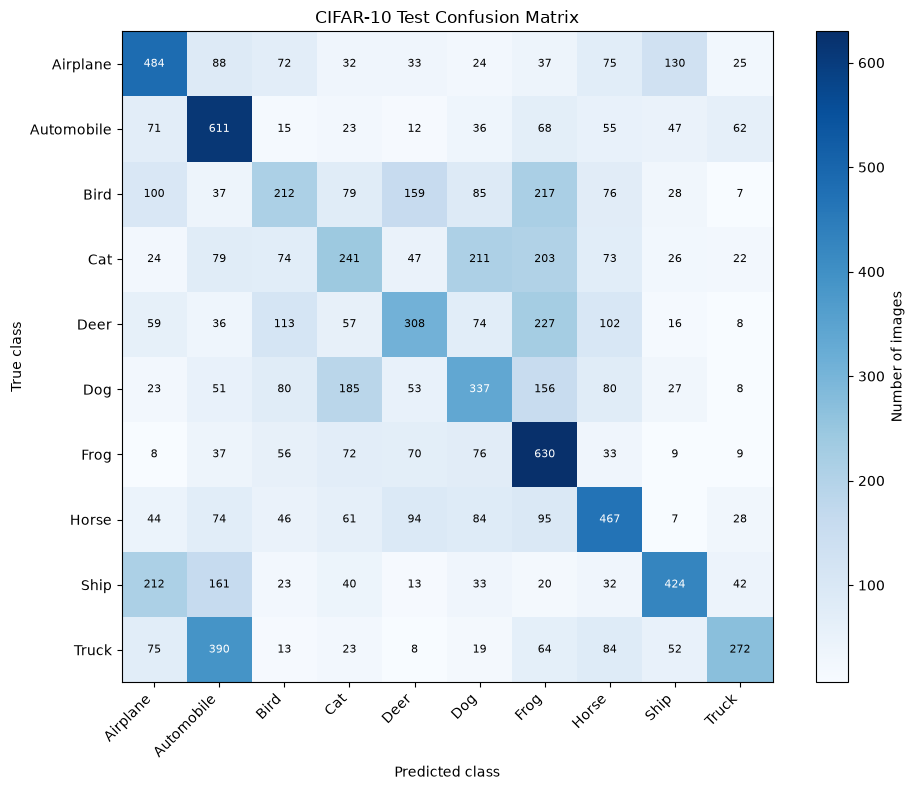

In [48]:
class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

# Rows = true classes; columns = predicted classes.
confusion = np.zeros((10, 10), dtype=int)
np.add.at(confusion, (y_test_final, y_pred), 1)

fig, ax = plt.subplots(figsize=(10, 8))

image = ax.imshow(confusion, interpolation="nearest", cmap="Blues")
fig.colorbar(image, ax=ax, label="Number of images")

ax.set(
    xticks=np.arange(10),
    yticks=np.arange(10),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted class",
    ylabel="True class",
    title="CIFAR-10 Test Confusion Matrix"
)

plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

threshold = confusion.max() / 2

for i in range(10):
    for j in range(10):
        ax.text(
            j, i, str(confusion[i, j]),
            ha="center",
            va="center",
            color="white" if confusion[i, j] > threshold else "black",
            fontsize=8
        )

plt.tight_layout()
plt.show()

### Limitations of Flattened-Pixel Fully Connected Networks

Flattening a CIFAR-10 image converts its 32 × 32 RGB grid into a
3072-dimensional vector. Although this preserves the pixel values and
colour channels, it does not explicitly preserve the two-dimensional
spatial structure of the image.

A fully connected network must learn useful relationships between
pixels through its weights and biases. It does not naturally exploit
local patterns such as edges, textures, and nearby-pixel relationships
as effectively as a convolutional architecture can. The network also
uses a large number of parameters and may require more data to
generalize well.

Therefore, a fully connected network trained on flattened pixels offers
a useful baseline, but it has important limitations for image
classification.